# 03 · The training loop — on the CPU, in a few minutes

**Read first:** `01_theory/06_data_training.md`

Your project trains the 4.9-million-parameter EmotionNet on the GPU for up to 50 epochs (~20 minutes, ~65%).
This notebook runs **the same loop** on any laptop, with a small network and a few epochs, so you can see every
piece working:

* `Dataset` + `DataLoader`, augmentation on training batches only
* class weights + label smoothing in the loss
* AdamW + a cosine learning-rate schedule
* validation every epoch, best checkpoint, early stopping
* the confusion matrix and per-class F1

In [1]:
import copy
import time
from pathlib import Path

import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Dataset

torch.manual_seed(42); np.random.seed(42)
torch.set_num_threads(max(1, torch.get_num_threads()))
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

ROOT = Path("../data/fer2013")
EMOTIONS = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]

def load_split(split):
    X, y = [], []
    for label, emotion in enumerate(EMOTIONS):
        for f in sorted((ROOT / split / emotion).iterdir()):
            X.append(cv2.imread(str(f), cv2.IMREAD_GRAYSCALE)); y.append(label)
    return np.stack(X), np.array(y)

X_all, y_all = load_split("train")
X_test, y_test = load_split("test")

# validation = 10% of the training folder, stratified
rng = np.random.default_rng(42)
val_mask = np.zeros(len(y_all), bool)
for c in range(7):
    rows = rng.permutation(np.flatnonzero(y_all == c))
    val_mask[rows[: len(rows) // 10]] = True
X_tr, y_tr, X_va, y_va = X_all[~val_mask], y_all[~val_mask], X_all[val_mask], y_all[val_mask]
print(f"train {len(y_tr)}   validation {len(y_va)}   test {len(y_test)}")

device: cpu


train 25841   validation 2868   test 7178


## 1. Dataset and DataLoader — and fast augmentation for the CPU

On the GPU your project uses the torchvision transforms of notebook 01 inside the `Dataset`, with
`num_workers=4` loading in parallel. On a CPU every millisecond counts, so here we normalise all images once,
wrap them in a `TensorDataset`, and augment **whole batches** at once (random horizontal flip + a random shift of
up to 4 pixels) — the same idea, 50× cheaper.

one batch: (128, 1, 48, 48) (128,)


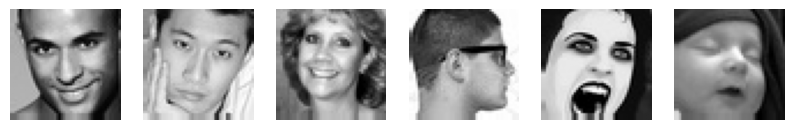

In [2]:
from torch.utils.data import TensorDataset

def to_tensor(X):
    return torch.tensor((X.astype(np.float32) / 255.0 - 0.5077) / 0.2550)[:, None]   # (N, 1, 48, 48)

train_loader = DataLoader(TensorDataset(to_tensor(X_tr), torch.tensor(y_tr)), batch_size=128, shuffle=True)
val_loader = DataLoader(TensorDataset(to_tensor(X_va), torch.tensor(y_va)), batch_size=512)
test_loader = DataLoader(TensorDataset(to_tensor(X_test), torch.tensor(y_test)), batch_size=512)

def augment(x):
    """Training only: flip half of the faces, shift the whole batch by up to 4 pixels."""
    flip = torch.rand(len(x)) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    padded = F.pad(x, (4, 4, 4, 4), mode="replicate")
    i, j = np.random.randint(0, 9, 2)
    return padded[:, :, i:i + 48, j:j + 48]

images, labels = next(iter(train_loader))
print("one batch:", tuple(images.shape), tuple(labels.shape))
fig, axes = plt.subplots(1, 6, figsize=(10, 2))
for a, img in zip(axes, augment(images[:6])):
    a.imshow(img[0], cmap="gray"); a.axis("off")
plt.show()

## 2. A small CNN (so it trains on a CPU)

Same ideas as EmotionNet — conv → BN → ReLU, stride to shrink, global average pooling, dropout, a linear head
returning logits — but it shrinks the image in its **first** layer, which makes it ~3× cheaper than a network
that keeps 48×48 for several layers, and it has ~12× fewer parameters than EmotionNet.

In [3]:
def conv_bn(c_in, c_out, stride):
    return nn.Sequential(nn.Conv2d(c_in, c_out, 3, stride, 1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU())

class SmallNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(conv_bn(1, 32, 2), conv_bn(32, 64, 1), conv_bn(64, 128, 2), conv_bn(128, 256, 2))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, 7))
    def forward(self, x):
        return self.head(self.features(x))

model = SmallNet().to(DEVICE)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")

390,119 parameters


## 3. Loss, optimiser, schedule

In [4]:
counts = np.bincount(y_tr, minlength=7)
class_weights = torch.tensor(len(y_tr) / (7 * counts), dtype=torch.float32)
class_weights = class_weights / class_weights.mean()
criterion = nn.CrossEntropyLoss(weight=class_weights.to(DEVICE), label_smoothing=0.1)

EPOCHS = 8
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
print("class weights:", dict(zip(EMOTIONS, class_weights.numpy().round(2))))

class weights: {'angry': np.float32(0.48), 'disgust': np.float32(4.4), 'fear': np.float32(0.47), 'happy': np.float32(0.27), 'neutral': np.float32(0.39), 'sad': np.float32(0.4), 'surprise': np.float32(0.61)}


## 4. The loop — train, validate, keep the best, stop early

In [5]:
def evaluate(model, loader):
    model.eval()                                    # Dropout off, BatchNorm uses its running stats
    preds, trues = [], []
    with torch.no_grad():
        for xb, yb in loader:
            preds.append(model(xb.to(DEVICE)).argmax(1).cpu()); trues.append(yb)
    return torch.cat(preds).numpy(), torch.cat(trues).numpy()

history, best_acc, best_state, patience, bad_epochs = [], 0.0, None, 4, 0
for epoch in range(1, EPOCHS + 1):
    model.train()
    t0, running = time.perf_counter(), 0.0
    for xb, yb in train_loader:
        xb, yb = augment(xb).to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()                             # gradients for every weight
        optimizer.step()                            # w = w - lr * (AdamW's version of the gradient)
        running += loss.item() * len(yb)
    scheduler.step()
    pred, true = evaluate(model, val_loader)
    acc = (pred == true).mean()
    history.append((running / len(y_tr), acc, scheduler.get_last_lr()[0]))
    print(f"epoch {epoch}: train loss {history[-1][0]:.3f}   val acc {acc:.3f}   lr {history[-1][2]:.5f}   ({time.perf_counter() - t0:.0f} s)")
    if acc > best_acc:
        best_acc, best_state, bad_epochs = acc, copy.deepcopy(model.state_dict()), 0     # "save the checkpoint"
    else:
        bad_epochs += 1
        if bad_epochs >= patience:
            print("early stopping"); break

_ = model.load_state_dict(best_state)

epoch 1: train loss 2.118   val acc 0.051   lr 0.00192   (81 s)


epoch 2: train loss 2.048   val acc 0.124   lr 0.00171   (70 s)


epoch 3: train loss 1.969   val acc 0.204   lr 0.00138   (71 s)


epoch 4: train loss 1.905   val acc 0.221   lr 0.00100   (70 s)


epoch 5: train loss 1.861   val acc 0.323   lr 0.00062   (71 s)


epoch 6: train loss 1.811   val acc 0.353   lr 0.00029   (70 s)


epoch 7: train loss 1.783   val acc 0.352   lr 0.00008   (70 s)


epoch 8: train loss 1.765   val acc 0.401   lr 0.00000   (70 s)


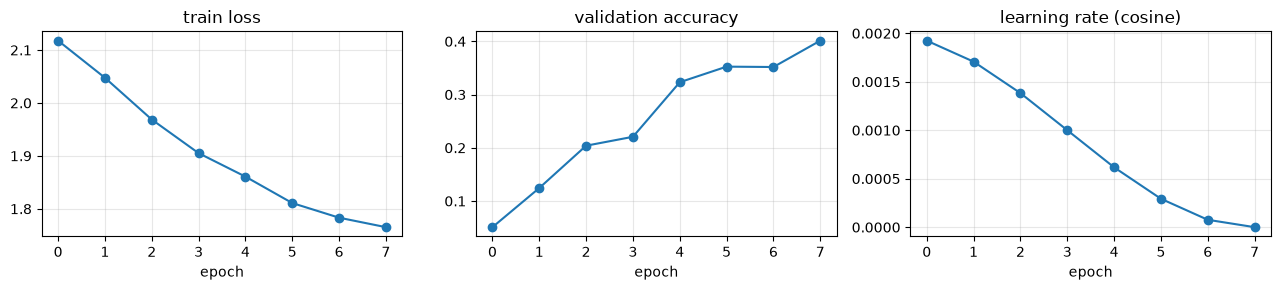

In [6]:
h = np.array(history)
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
axes[0].plot(h[:, 0], marker="o"); axes[0].set_title("train loss")
axes[1].plot(h[:, 1], marker="o"); axes[1].set_title("validation accuracy")
axes[2].plot(h[:, 2], marker="o"); axes[2].set_title("learning rate (cosine)")
for a in axes: a.set_xlabel("epoch"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 5. The test set — once, at the end

test accuracy 0.409   (a few CPU epochs of a small net; your GPU EmotionNet target: >= 0.65)

          precision recall    F1
angry       0.39     0.21    0.27
disgust     0.04     0.83    0.08
fear        0.32     0.08    0.13
happy       0.81     0.59    0.69
neutral     0.46     0.47    0.47
sad         0.43     0.24    0.31
surprise    0.57     0.75    0.65


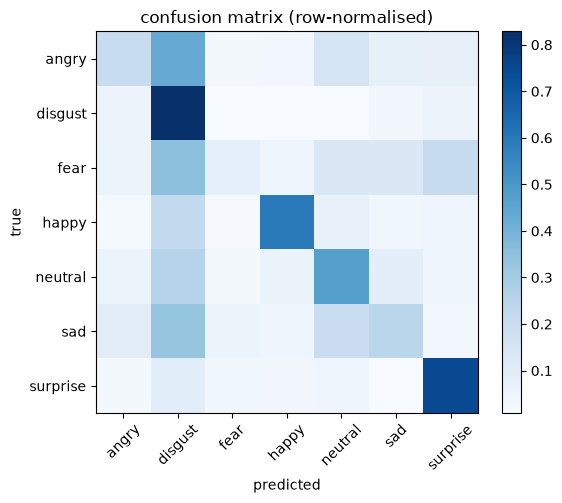

In [7]:
pred, true = evaluate(model, test_loader)
cm = np.zeros((7, 7), int)
np.add.at(cm, (true, pred), 1)
print(f"test accuracy {np.mean(pred == true):.3f}   (a few CPU epochs of a small net; your GPU EmotionNet target: >= 0.65)\n")
print(f"{'':9s} precision recall    F1")
for c, e in enumerate(EMOTIONS):
    p = cm[c, c] / max(cm[:, c].sum(), 1); r = cm[c, c] / max(cm[c].sum(), 1)
    print(f"{e:9s}   {p:.2f}     {r:.2f}    {0 if p + r == 0 else 2 * p * r / (p + r):.2f}")

plt.figure(figsize=(6, 5))
plt.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues")
plt.xticks(range(7), EMOTIONS, rotation=45); plt.yticks(range(7), EMOTIONS)
plt.xlabel("predicted"); plt.ylabel("true"); plt.colorbar(); plt.title("confusion matrix (row-normalised)")
plt.tight_layout(); plt.show()

torch.save(model.state_dict(), "../data/_smallnet.pt")      # notebook 04 uses it

Read the matrix like your book will: which emotions are confused with which? Happy and surprise are the easiest.

Look at **disgust**: high recall, tiny precision — the model calls many faces "disgust". That is the class weight
(×4.4 here) at work on a model that is still young: a mistake on disgust is so expensive that, after a few epochs, the
safest bet is to over-call it. With full training this balances out; if it does not in your project, try softer
weights (e.g. the square root of these). That is exactly the kind of finding the results chapter is for.

## ✍️ Try it yourself

1. Train once **without** class weights. What happens to the recall of disgust?
2. Set `label_smoothing=0`. Is the final accuracy different? Look at the confidence of the predictions.
3. Replace `SmallNet` with the `EmotionNet` from notebook 02 and train **one** epoch. How much slower is it on
   your machine? Now you know why the project uses the GPU.

Then solve exercises 8–10 in `03_exercises/`.